<a href="https://colab.research.google.com/github/glakkisetty-sfbu/cs250-fall2026-geethika-lakkisetty/blob/main/Resume_Matcher_Explained_Working_Prototype_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Resume vs. Internship Description Matcher — Explained Code + Working Prototype

**Google Colab notebook** | Complete source-code explanation, interactive prototype, graphs, tests, and AI log.

**How to use:** In Colab select **Runtime → Run all**, then scroll to **Interactive Prototype**. Edit the two text boxes and click **Compare Resume & Posting**. No API key or external service is required. The notebook includes a sample for demonstration; it is not a real applicant's resume.

**Scope:** Curated keyword detection only. Missing terms are prompts for review, not proof of missing experience, ATS scores, or hiring predictions.


## Part A — Every line of the original matcher explained
The next sections reproduce the code from your previous Colab notebook. The tables explain every executable source line; empty lines are only for readability. Indented lines belong to the block above them.

### Imports — original lines 1–1

In [1]:
import argparse

| Original line | Code | Explanation |
|---:|---|---|
| 1 | `import argparse` | Imports command-line argument parsing (used in the standalone script, not needed for the notebook demo). |

### Imports — original lines 2–3

In [5]:

import re

| Original line | Code | Explanation |
|---:|---|---|
| 3 | `import re` | Imports regular expressions for text normalization and phrase matching. |

### Imports — original lines 4–5

In [6]:

from pathlib import Path

| Original line | Code | Explanation |
|---:|---|---|
| 5 | `from pathlib import Path` | Imports a file-path helper for reading UTF-8 text files. |

### Skill dictionary — original lines 6–12

In [7]:

SKILLS = {
    "Programming Languages": ["Python", "Java", "JavaScript", "C++", "C#", "R", "SQL", "HTML", "CSS"],
    "Tools and Technologies": ["Excel", "Tableau", "Power BI", "Git", "GitHub", "AWS", "Docker", "Jupyter", "Pandas", "NumPy"],
    "Data and Research": ["Data analysis", "Data visualization", "Machine learning", "Statistics", "Research", "Data cleaning"],
    "Transferable Skills": ["Communication", "Teamwork", "Problem solving", "Leadership", "Time management", "Collaboration", "Presentation"],
}

| Original line | Code | Explanation |
|---:|---|---|
| 7 | `SKILLS = {` | Starts the curated dictionary; category names map to lists of recognized skills. |
| 8 | `"Programming Languages": ["Python", "Java", "JavaScript", "C++", "C#", "R", "SQL", "HTML", "CSS"],` | Defines the list of recognized skills in this category. |
| 9 | `"Tools and Technologies": ["Excel", "Tableau", "Power BI", "Git", "GitHub", "AWS", "Docker", "Jupyter", "Pandas", "NumPy"],` | Defines the list of recognized skills in this category. |
| 10 | `"Data and Research": ["Data analysis", "Data visualization", "Machine learning", "Statistics", "Research", "Data cleaning"],` | Defines the list of recognized skills in this category. |
| 11 | `"Transferable Skills": ["Communication", "Teamwork", "Problem solving", "Leadership", "Time management", "Collaboration", "Presentation"],` | Defines the list of recognized skills in this category. |
| 12 | `}` | Closes the dictionary, list, or function call opened earlier. |

### Skill aliases — original lines 13–25

In [8]:

ALIASES = {
    "JavaScript": ["javascript", "java script"],
    "C++": ["c++"],
    "C#": ["c#"],
    "Power BI": ["power bi", "powerbi"],
    "GitHub": ["github", "git hub"],
    "NumPy": ["numpy"],
    "Pandas": ["pandas"],
    "Problem solving": ["problem solving", "problem-solving"],
    "Data visualization": ["data visualization", "data visualisation"],
    "Teamwork": ["teamwork", "team work"],
}

| Original line | Code | Explanation |
|---:|---|---|
| 14 | `ALIASES = {` | Starts the dictionary of alternate spellings for canonical skill labels. |
| 15 | `"JavaScript": ["javascript", "java script"],` | Defines the list of recognized skills in this category. |
| 16 | `"C++": ["c++"],` | Defines the list of recognized skills in this category. |
| 17 | `"C#": ["c#"],` | Defines the list of recognized skills in this category. |
| 18 | `"Power BI": ["power bi", "powerbi"],` | Defines the list of recognized skills in this category. |
| 19 | `"GitHub": ["github", "git hub"],` | Defines the list of recognized skills in this category. |
| 20 | `"NumPy": ["numpy"],` | Defines the list of recognized skills in this category. |
| 21 | `"Pandas": ["pandas"],` | Defines the list of recognized skills in this category. |
| 22 | `"Problem solving": ["problem solving", "problem-solving"],` | Defines the list of recognized skills in this category. |
| 23 | `"Data visualization": ["data visualization", "data visualisation"],` | Defines the list of recognized skills in this category. |
| 24 | `"Teamwork": ["teamwork", "team work"],` | Defines the list of recognized skills in this category. |
| 25 | `}` | Closes the dictionary, list, or function call opened earlier. |

### read_file() — original lines 26–29

In [9]:

def read_file(path):
    """Read a UTF-8 plain-text document and return its contents."""
    return Path(path).read_text(encoding="utf-8-sig")

| Original line | Code | Explanation |
|---:|---|---|
| 27 | `def read_file(path):` | Defines a function taking the path of a plain-text file. |
| 28 | `"""Read a UTF-8 plain-text document and return its contents."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 29 | `return Path(path).read_text(encoding="utf-8-sig")` | Reads the file as UTF-8 text; utf-8-sig also handles a UTF-8 byte-order mark. |

### clean_text() — original lines 30–38

In [10]:

def clean_text(text):
    """Lowercase and normalize punctuation/whitespace for matching.

    Preserve + and # because they distinguish programming language names.
    """
    text = text.casefold()
    text = re.sub(r"[^\w\s+#]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

| Original line | Code | Explanation |
|---:|---|---|
| 31 | `def clean_text(text):` | Defines a function to normalize input before matching. |
| 32 | `"""Lowercase and normalize punctuation/whitespace for matching.` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 34 | `Preserve + and # because they distinguish programming language names.` | Continues the expression or data structure from the surrounding lines. |
| 35 | `"""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 36 | `text = text.casefold()` | Converts text to a Unicode-aware lowercase form. |
| 37 | `text = re.sub(r"[^\w\s+#]", " ", text)` | Replaces punctuation with spaces while keeping + and # for skills such as C++ and C#. |
| 38 | `return re.sub(r"\s+", " ", text).strip()` | Collapses repeated whitespace to a single space and removes leading/trailing whitespace. |

### skill_pattern() — original lines 39–44

In [11]:

def skill_pattern(phrase):
    """Match a skill as a whole term or phrase, not inside another word."""
    words = clean_text(phrase).split()
    body = r"\s+".join(re.escape(word) for word in words)
    return re.compile(r"(?<!\w)" + body + r"(?!\w)", flags=re.IGNORECASE)

| Original line | Code | Explanation |
|---:|---|---|
| 40 | `def skill_pattern(phrase):` | Defines a function that builds a whole-word/whole-phrase regex. |
| 41 | `"""Match a skill as a whole term or phrase, not inside another word."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 42 | `words = clean_text(phrase).split()` | Cleans the skill phrase and splits it into words. |
| 43 | `body = r"\s+".join(re.escape(word) for word in words)` | Escapes each word for regex safety and joins words with a flexible whitespace pattern. |
| 44 | `return re.compile(r"(?<!\w)" + body + r"(?!\w)", flags=re.IGNORECASE)` | Compiles a case-insensitive pattern with word boundaries so a skill is not found inside another word. |

### extract_skills() — original lines 45–55

In [12]:

def extract_skills(text, skills=SKILLS):
    """Return canonical skills detected in the supplied text."""
    normalized = clean_text(text)
    found = set()
    for labels in skills.values():
        for label in labels:
            alternatives = ALIASES.get(label, [label])
            if any(skill_pattern(alt).search(normalized) for alt in alternatives):
                found.add(label)
    return found

| Original line | Code | Explanation |
|---:|---|---|
| 46 | `def extract_skills(text, skills=SKILLS):` | Defines the function that returns a set of detected canonical skill labels. |
| 47 | `"""Return canonical skills detected in the supplied text."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 48 | `normalized = clean_text(text)` | Stores the cleaned version of the text or sentence. |
| 49 | `found = set()` | Creates an empty set to avoid counting duplicate skill mentions. |
| 50 | `for labels in skills.values():` | Loops over each category’s list of skills. |
| 51 | `for label in labels:` | Loops through each skill in the current category. |
| 52 | `alternatives = ALIASES.get(label, [label])` | Gets the known aliases for a skill; if none exist, uses its label. |
| 53 | `if any(skill_pattern(alt).search(normalized) for alt in alternatives):` | Tests whether any alternative spelling matches this text. |
| 54 | `found.add(label)` | Adds the canonical skill name to the result set. |
| 55 | `return found` | Returns all uniquely detected skill labels. |

### compare_skills() — original lines 56–59

In [13]:

def compare_skills(resume_skills, posting_skills):
    """Return (matched, posting_terms_not_detected) as sorted lists."""
    return sorted(resume_skills & posting_skills), sorted(posting_skills - resume_skills)

| Original line | Code | Explanation |
|---:|---|---|
| 57 | `def compare_skills(resume_skills, posting_skills):` | Defines set comparison for matches and posting-only skills. |
| 58 | `"""Return (matched, posting_terms_not_detected) as sorted lists."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 59 | `return sorted(resume_skills & posting_skills), sorted(posting_skills - resume_skills)` | Returns sorted intersection (matched) and difference (posting-only) lists. |

### split_evidence() — original lines 60–63

In [14]:

def split_evidence(text):
    """Split on lines and sentence-ending punctuation while preserving source wording."""
    return [part.strip(" \t\r\n-•") for part in re.split(r"(?:\r?\n)+|(?<=[.!?])\s+", text) if part.strip(" \t\r\n-•")]

| Original line | Code | Explanation |
|---:|---|---|
| 61 | `def split_evidence(text):` | Defines a helper to divide the original resume into lines or sentences. |
| 62 | `"""Split on lines and sentence-ending punctuation while preserving source wording."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 63 | `return [part.strip(" \t\r\n-•") for part in re.split(r"(?:\r?\n)+\|(?<=[.!?])\s+", text) if part.strip(" \t\r\n-•")]` | Splits text at line breaks or sentence endings, trims bullets/spaces, and discards empty segments. |

### find_evidence() — original lines 64–75

In [15]:

def find_evidence(resume_text, matched_skills):
    """Find the first original resume line/sentence supporting each matched skill."""
    segments = split_evidence(resume_text)
    evidence = {}
    for label in matched_skills:
        for segment in segments:
            normalized = clean_text(segment)
            if any(skill_pattern(alt).search(normalized) for alt in ALIASES.get(label, [label])):
                evidence[label] = segment
                break
    return evidence

| Original line | Code | Explanation |
|---:|---|---|
| 65 | `def find_evidence(resume_text, matched_skills):` | Defines a function to locate supporting resume text for each matched skill. |
| 66 | `"""Find the first original resume line/sentence supporting each matched skill."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 67 | `segments = split_evidence(resume_text)` | Splits the original resume into searchable evidence segments. |
| 68 | `evidence = {}` | Creates a dictionary that will map skills to supporting sentences. |
| 69 | `for label in matched_skills:` | Loops over matched skills to find evidence for each. |
| 70 | `for segment in segments:` | Checks each original resume sentence or line. |
| 71 | `normalized = clean_text(segment)` | Stores the cleaned version of the text or sentence. |
| 72 | `if any(skill_pattern(alt).search(normalized) for alt in ALIASES.get(label, [label])):` | Tests whether any alternative spelling matches this text. |
| 73 | `evidence[label] = segment` | Records the first original resume segment that mentions the skill. |
| 74 | `break` | Stops looking for further evidence for this skill after the first match. |
| 75 | `return evidence` | Returns the dictionary of evidence sentences. |

### group_skills() — original lines 76–81

In [16]:

def group_skills(labels, skills=SKILLS):
    """Group a collection of canonical skill names by category."""
    selected = set(labels)
    return {category: [skill for skill in entries if skill in selected]
            for category, entries in skills.items() if selected.intersection(entries)}

| Original line | Code | Explanation |
|---:|---|---|
| 77 | `def group_skills(labels, skills=SKILLS):` | Defines a helper to organize selected skills by category. |
| 78 | `"""Group a collection of canonical skill names by category."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 79 | `selected = set(labels)` | Converts selected skill labels to a set for fast membership checking. |
| 80 | `return {category: [skill for skill in entries if skill in selected]` | Starts a dictionary comprehension grouping selected skills by category. |
| 81 | `for category, entries in skills.items() if selected.intersection(entries)}` | Iterates through the category names and skill lists, retaining categories with matches. |

### format_results() — original lines 82–111

In [17]:

def format_results(matched, missing, evidence):
    """Build a cautious, readable text report."""
    lines = ["RESUME VS. INTERNSHIP DESCRIPTION MATCHER", "=" * 45, ""]
    lines.append("MATCHED SKILLS (found in both documents)")
    if matched:
        for category, labels in group_skills(matched).items():
            lines.append(f"  {category}:")
            lines.extend(f"    - {label}" for label in labels)
    else:
        lines.append("  No curated skills detected in both documents.")
    lines.extend(["", "POSTING TERMS TO REVIEW (not detected in resume)"])
    if missing:
        for category, labels in group_skills(missing).items():
            lines.append(f"  {category}:")
            lines.extend(f"    - {label}" for label in labels)
    else:
        lines.append("  No additional curated posting skills detected.")
    lines.extend(["", "RESUME EVIDENCE FOR MATCHED SKILLS"])
    if evidence:
        for label in matched:
            if label in evidence:
                lines.append(f"  {label}: {evidence[label]}")
    else:
        lines.append("  No supporting sentences found.")
    lines.extend(["", "SUMMARY", f"  Matched curated skills: {len(matched)}",
                  f"  Posting terms to review: {len(missing)}", "",
                  "These are keyword detections, not an ATS score or hiring prediction.",
                  "Only update your resume with experience you genuinely have."])
    return "\n".join(lines)

| Original line | Code | Explanation |
|---:|---|---|
| 83 | `def format_results(matched, missing, evidence):` | Defines the function that produces the readable text report. |
| 84 | `"""Build a cautious, readable text report."""` | Function docstring: explains the purpose of this function; it is not a matching operation. |
| 85 | `lines = ["RESUME VS. INTERNSHIP DESCRIPTION MATCHER", "=" * 45, ""]` | Starts the formatted report as a list of text lines. |
| 86 | `lines.append("MATCHED SKILLS (found in both documents)")` | Appends one heading or report line. |
| 87 | `if matched:` | Uses the matched-skills section when at least one match exists. |
| 88 | `for category, labels in group_skills(matched).items():` | Loops over the grouped categories and their skill lists. |
| 89 | `lines.append(f"  {category}:")` | Appends one heading or report line. |
| 90 | `lines.extend(f"    - {label}" for label in labels)` | Appends several lines to the report. |
| 91 | `else:` | Handles the case where the preceding condition was false. |
| 92 | `lines.append("  No curated skills detected in both documents.")` | Appends one heading or report line. |
| 93 | `lines.extend(["", "POSTING TERMS TO REVIEW (not detected in resume)"])` | Appends several lines to the report. |
| 94 | `if missing:` | Uses the posting-terms section when at least one term needs review. |
| 95 | `for category, labels in group_skills(missing).items():` | Loops over the grouped categories and their skill lists. |
| 96 | `lines.append(f"  {category}:")` | Appends one heading or report line. |
| 97 | `lines.extend(f"    - {label}" for label in labels)` | Appends several lines to the report. |
| 98 | `else:` | Handles the case where the preceding condition was false. |
| 99 | `lines.append("  No additional curated posting skills detected.")` | Appends one heading or report line. |
| 100 | `lines.extend(["", "RESUME EVIDENCE FOR MATCHED SKILLS"])` | Appends several lines to the report. |
| 101 | `if evidence:` | Checks whether any supporting resume evidence was found. |
| 102 | `for label in matched:` | Loops through matched skills to print supporting evidence. |
| 103 | `if label in evidence:` | Only prints evidence for skills that have a recorded sentence. |
| 104 | `lines.append(f"  {label}: {evidence[label]}")` | Appends one heading or report line. |
| 105 | `else:` | Handles the case where the preceding condition was false. |
| 106 | `lines.append("  No supporting sentences found.")` | Appends one heading or report line. |
| 107 | `lines.extend(["", "SUMMARY", f"  Matched curated skills: {len(matched)}",` | Appends several lines to the report. |
| 108 | `f"  Posting terms to review: {len(missing)}", "",` | Continues the expression or data structure from the surrounding lines. |
| 109 | `"These are keyword detections, not an ATS score or hiring prediction.",` | A text value, skill list entry, or line included in the report. |
| 110 | `"Only update your resume with experience you genuinely have."])` | A text value, skill list entry, or line included in the report. |
| 111 | `return "\n".join(lines)` | Combines report lines into a single multiline string. |

### Sample resume and posting

In [18]:
resume_text = 'SKILLS\nPython, SQL, Excel, teamwork\nPROJECT EXPERIENCE\nUsed Python and SQL for data cleaning and data analysis.\nCollaborated with classmates to present findings.\n'
posting_text = 'Data Analyst Intern\nWe are seeking applicants with Python, SQL, Tableau, data analysis, and teamwork skills.\nStrong communication skills are also valuable.\n'
print("Sample input loaded.")

Sample input loaded.


| Line | Code | What it does |
|---:|---|---|
| 1 | `resume_text = 'SKILLS\nPython, SQL, Excel, teamwork\nPROJECT EXPERIENCE\nUsed Python and SQL for data cleaning and data analysis.\nCollaborated with classmates to present findings.\n'` | Stores a sample resume as a multiline string (\n means a new line). |
| 2 | `posting_text = 'Data Analyst Intern\nWe are seeking applicants with Python, SQL, Tableau, data analysis, and teamwork skills.\nStrong communication skills are also valuable.\n'` | Stores the sample internship description. |
| 3 | `print("Sample input loaded.")` | Displays a message or the formatted results. |

### Run the matcher and display results

In [19]:
if not resume_text.strip() or not posting_text.strip():
    raise ValueError("Both documents must contain text.")
resume_skills = extract_skills(resume_text)
posting_skills = extract_skills(posting_text)
matched, missing = compare_skills(resume_skills, posting_skills)
evidence = find_evidence(resume_text, matched)
print(format_results(matched, missing, evidence))

RESUME VS. INTERNSHIP DESCRIPTION MATCHER

MATCHED SKILLS (found in both documents)
  Programming Languages:
    - Python
    - SQL
  Data and Research:
    - Data analysis
  Transferable Skills:
    - Teamwork

POSTING TERMS TO REVIEW (not detected in resume)
  Tools and Technologies:
    - Tableau
  Transferable Skills:
    - Communication

RESUME EVIDENCE FOR MATCHED SKILLS
  Data analysis: Used Python and SQL for data cleaning and data analysis.
  Python: Python, SQL, Excel, teamwork
  SQL: Python, SQL, Excel, teamwork
  Teamwork: Python, SQL, Excel, teamwork

SUMMARY
  Matched curated skills: 4
  Posting terms to review: 2

These are keyword detections, not an ATS score or hiring prediction.
Only update your resume with experience you genuinely have.


| Line | Code | What it does |
|---:|---|---|
| 1 | `if not resume_text.strip() or not posting_text.strip():` | Checks that neither input is empty. |
| 2 | `raise ValueError("Both documents must contain text.")` | Stops with an error if the inputs are blank. |
| 3 | `resume_skills = extract_skills(resume_text)` | Extracts skills from the resume. |
| 4 | `posting_skills = extract_skills(posting_text)` | Extracts skills from the internship description. |
| 5 | `matched, missing = compare_skills(resume_skills, posting_skills)` | Finds the common skills and posting-only terms. |
| 6 | `evidence = find_evidence(resume_text, matched)` | Finds resume sentences supporting matched terms. |
| 7 | `print(format_results(matched, missing, evidence))` | Displays a message or the formatted results. |

### Graph 1: matched vs. review terms

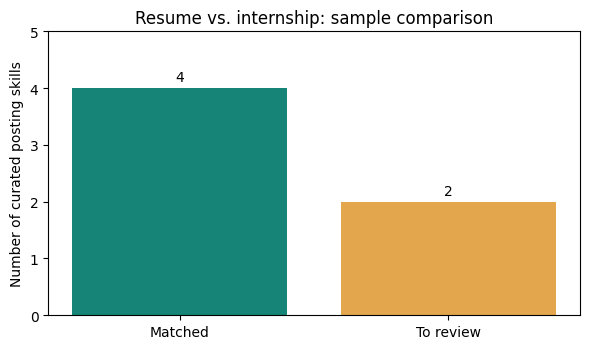

In [20]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.6))
labels = ["Matched", "To review"]
counts = [len(matched), len(missing)]
bars = ax.bar(labels, counts, color=["#168477", "#e3a64d"])
ax.bar_label(bars, padding=3)
ax.set_ylabel("Number of curated posting skills")
ax.set_title("Resume vs. internship: sample comparison")
ax.set_ylim(0, max(counts + [1]) + 1)
plt.tight_layout()
plt.show()

| Line | Code | What it does |
|---:|---|---|
| 1 | `import matplotlib.pyplot as plt` | Imports the charting library. |
| 2 | `fig, ax = plt.subplots(figsize=(6, 3.6))` | Creates a chart figure and axes with the specified dimensions. |
| 3 | `labels = ["Matched", "To review"]` | Names the chart bars. |
| 4 | `counts = [len(matched), len(missing)]` | Counts the matched skills and terms to review. |
| 5 | `bars = ax.bar(labels, counts, color=["#168477", "#e3a64d"])` | Draws the vertical bar chart. |
| 6 | `ax.bar_label(bars, padding=3)` | Writes numbers above the bars. |
| 7 | `ax.set_ylabel("Number of curated posting skills")` | Labels the vertical axis. |
| 8 | `ax.set_title("Resume vs. internship: sample comparison")` | Sets the chart title. |
| 9 | `ax.set_ylim(0, max(counts + [1]) + 1)` | Adds vertical space above the tallest bar. |
| 10 | `plt.tight_layout()` | Adjusts plot spacing to avoid overlap. |
| 11 | `plt.show()` | Displays the chart. |

### Graph 2: skill categories

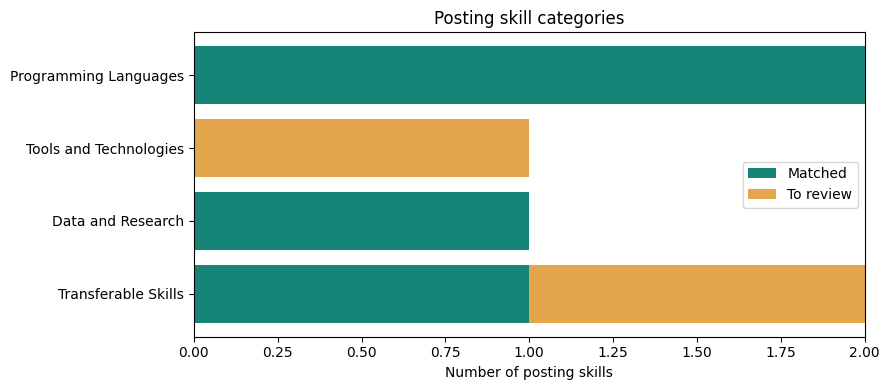

In [21]:
categories = list(SKILLS)
matched_by_category = [len(set(SKILLS[c]) & set(matched)) for c in categories]
missing_by_category = [len(set(SKILLS[c]) & set(missing)) for c in categories]
fig, ax = plt.subplots(figsize=(9, 4))
y = list(range(len(categories)))
ax.barh(y, matched_by_category, label="Matched", color="#168477")
ax.barh(y, missing_by_category, left=matched_by_category, label="To review", color="#e3a64d")
ax.set_yticks(y, categories)
ax.invert_yaxis()
ax.set_xlabel("Number of posting skills")
ax.legend()
ax.set_title("Posting skill categories")
plt.tight_layout()
plt.show()

| Line | Code | What it does |
|---:|---|---|
| 1 | `categories = list(SKILLS)` | Collects the skill category names. |
| 2 | `matched_by_category = [len(set(SKILLS[c]) & set(matched)) for c in categories]` | Counts matched skills within each category. |
| 3 | `missing_by_category = [len(set(SKILLS[c]) & set(missing)) for c in categories]` | Counts posting-only skills within each category. |
| 4 | `fig, ax = plt.subplots(figsize=(9, 4))` | Creates a chart figure and axes with the specified dimensions. |
| 5 | `y = list(range(len(categories)))` | Creates numeric positions for the category bars. |
| 6 | `ax.barh(y, matched_by_category, label="Matched", color="#168477")` | Draws horizontal matched-skill bars. |
| 7 | `ax.barh(y, missing_by_category, left=matched_by_category, label="To review", color="#e3a64d")` | Stacks review-term bars after matched bars. |
| 8 | `ax.set_yticks(y, categories)` | Labels each category on the vertical axis. |
| 9 | `ax.invert_yaxis()` | Shows the first category at the top. |
| 10 | `ax.set_xlabel("Number of posting skills")` | Labels the horizontal axis. |
| 11 | `ax.legend()` | Shows what the bar colors mean. |
| 12 | `ax.set_title("Posting skill categories")` | Sets the chart title. |
| 13 | `plt.tight_layout()` | Adjusts plot spacing to avoid overlap. |
| 14 | `plt.show()` | Displays the chart. |

### Six original checks

In [22]:
assert "Python" in extract_skills("Python and SQL")
assert "R" not in extract_skills("research")
assert "Data analysis" in extract_skills("I did data analysis.")
assert compare_skills({"Python", "SQL"}, {"SQL", "Tableau"}) == (["SQL"], ["Tableau"])
assert "Python" in find_evidence("Used Python for research.", ["Python"])
assert len(matched) == 4 and len(missing) == 2, "Sample results changed"
print("6 notebook checks passed")

6 notebook checks passed


| Line | Code | What it does |
|---:|---|---|
| 1 | `assert "Python" in extract_skills("Python and SQL")` | Checks a required behavior; raises AssertionError if false. |
| 2 | `assert "R" not in extract_skills("research")` | Checks a required behavior; raises AssertionError if false. |
| 3 | `assert "Data analysis" in extract_skills("I did data analysis.")` | Checks a required behavior; raises AssertionError if false. |
| 4 | `assert compare_skills({"Python", "SQL"}, {"SQL", "Tableau"}) == (["SQL"], ["Tableau"])` | Checks a required behavior; raises AssertionError if false. |
| 5 | `assert "Python" in find_evidence("Used Python for research.", ["Python"])` | Checks a required behavior; raises AssertionError if false. |
| 6 | `assert len(matched) == 4 and len(missing) == 2, "Sample results changed"` | Checks a required behavior; raises AssertionError if false. |
| 7 | `print("6 notebook checks passed")` | Displays a message or the formatted results. |

## Part B — Working interactive prototype

This adds a small user interface to the **same matching functions** above. It uses `ipywidgets`, which works directly inside Google Colab. You can paste your own text, click the button, and immediately see matched skills, terms to review, evidence, and a graph. It does **not** upload your text to an external matching service.

**Demo steps:** Run all cells → edit either text box → click **Compare Resume & Posting** → inspect the report and graph. For a live demo, change `Tableau` in the resume and click again to see the review count decrease.


### Prototype dependency
Run the next cell once to install `ipywidgets` if it is not already available in your Colab runtime.

In [23]:
%pip -q install ipywidgets

In [24]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import matplotlib.pyplot as plt

resume_box = widgets.Textarea(value=resume_text, description="Resume:",
                              placeholder="Paste resume text here", layout=widgets.Layout(width="100%", height="170px"),
                              style={"description_width": "95px"})
posting_box = widgets.Textarea(value=posting_text, description="Internship:",
                               placeholder="Paste internship description here", layout=widgets.Layout(width="100%", height="170px"),
                               style={"description_width": "95px"})
compare_button = widgets.Button(description="Compare Resume & Posting", button_style="primary",
                                icon="search", layout=widgets.Layout(width="260px"))
reset_button = widgets.Button(description="Reset sample", icon="refresh")
results_area = widgets.Output()

def on_compare_clicked(button):
    with results_area:
        clear_output(wait=True)
        resume = resume_box.value
        posting = posting_box.value
        if not resume.strip() or not posting.strip():
            print("Please enter both a resume and an internship description.")
            return
        resume_found = extract_skills(resume)
        posting_found = extract_skills(posting)
        matched_now, review_now = compare_skills(resume_found, posting_found)
        evidence_now = find_evidence(resume, matched_now)
        print(format_results(matched_now, review_now, evidence_now))
        fig, ax = plt.subplots(figsize=(6, 3.3))
        bars = ax.bar(["Matched", "To review"], [len(matched_now), len(review_now)],
                      color=["#168477", "#e3a64d"])
        ax.bar_label(bars, padding=3)
        ax.set_ylabel("Number of posting skills")
        ax.set_ylim(0, max(len(matched_now), len(review_now), 1) + 1)
        ax.set_title("Current input comparison")
        plt.tight_layout()
        plt.show()

def on_reset_clicked(button):
    resume_box.value = resume_text
    posting_box.value = posting_text
    on_compare_clicked(button)

compare_button.on_click(on_compare_clicked)
reset_button.on_click(on_reset_clicked)
display(widgets.HTML("<h3>Resume vs. Internship Description Matcher</h3><p>Paste both texts and compare curated skills.</p>"),
        resume_box, posting_box, widgets.HBox([compare_button, reset_button]), results_area)
on_compare_clicked(None)


HTML(value='<h3>Resume vs. Internship Description Matcher</h3><p>Paste both texts and compare curated skills.<…

Textarea(value='SKILLS\nPython, SQL, Excel, teamwork\nPROJECT EXPERIENCE\nUsed Python and SQL for data cleanin…

Textarea(value='Data Analyst Intern\nWe are seeking applicants with Python, SQL, Tableau, data analysis, and t…

Output()

### Interactive prototype — line-by-line explanation

| Line | Code | Explanation |
|---:|---|---|
| 1 | `import ipywidgets as widgets` | Imports Colab-compatible interactive form controls. |
| 2 | `from IPython.display import display, clear_output` | Imports display and output-clearing helpers. |
| 3 | `import matplotlib.pyplot as plt` | Imports graph plotting. |
| 5 | `resume_box = widgets.Textarea(value=resume_text, description="Resume:",` | Creates the resume text-entry box with sample text. |
| 6 | `placeholder="Paste resume text here", layout=widgets.Layout(width="100%", height="170px"),` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 7 | `style={"description_width": "95px"})` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 8 | `posting_box = widgets.Textarea(value=posting_text, description="Internship:",` | Creates the internship text-entry box. |
| 9 | `placeholder="Paste internship description here", layout=widgets.Layout(width="100%", height="170px"),` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 10 | `style={"description_width": "95px"})` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 11 | `compare_button = widgets.Button(description="Compare Resume & Posting", button_style="primary",` | Creates the button to start a comparison. |
| 12 | `icon="search", layout=widgets.Layout(width="260px"))` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 13 | `reset_button = widgets.Button(description="Reset sample", icon="refresh")` | Creates a button to restore sample inputs. |
| 14 | `results_area = widgets.Output()` | Creates a dedicated area for results and charts. |
| 16 | `def on_compare_clicked(button):` | Defines what happens when the Compare button is clicked. |
| 17 | `with results_area:` | Routes printed text and charts to the results area. |
| 18 | `clear_output(wait=True)` | Clears the previous results before displaying new ones. |
| 19 | `resume = resume_box.value` | Reads the current resume box text. |
| 20 | `posting = posting_box.value` | Reads the current internship box text. |
| 21 | `if not resume.strip() or not posting.strip():` | Validates that both boxes contain non-whitespace text. |
| 22 | `print("Please enter both a resume and an internship description.")` | Displays a validation message. |
| 23 | `return` | Exits the callback early when input is invalid. |
| 24 | `resume_found = extract_skills(resume)` | Extracts resume skills with the original matcher. |
| 25 | `posting_found = extract_skills(posting)` | Extracts posting skills with the original matcher. |
| 26 | `matched_now, review_now = compare_skills(resume_found, posting_found)` | Compares the two skill sets. |
| 27 | `evidence_now = find_evidence(resume, matched_now)` | Finds original resume evidence for matches. |
| 28 | `print(format_results(matched_now, review_now, evidence_now))` | Prints the text report. |
| 29 | `fig, ax = plt.subplots(figsize=(6, 3.3))` | Creates the chart and axes. |
| 30 | `bars = ax.bar(["Matched", "To review"], [len(matched_now), len(review_now)],` | Draws matched and review bars. |
| 31 | `color=["#168477", "#e3a64d"])` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 32 | `ax.bar_label(bars, padding=3)` | Shows bar counts. |
| 33 | `ax.set_ylabel("Number of posting skills")` | Labels the count axis. |
| 34 | `ax.set_ylim(0, max(len(matched_now), len(review_now), 1) + 1)` | Makes the y-axis tall enough for both bars. |
| 35 | `ax.set_title("Current input comparison")` | Sets the chart title. |
| 36 | `plt.tight_layout()` | Prevents labels from overlapping. |
| 37 | `plt.show()` | Renders the chart. |
| 39 | `def on_reset_clicked(button):` | Defines what happens when Reset is clicked. |
| 40 | `resume_box.value = resume_text` | Restores the sample resume text. |
| 41 | `posting_box.value = posting_text` | Restores the sample posting text. |
| 42 | `on_compare_clicked(button)` | Reruns the comparison after resetting. |
| 44 | `compare_button.on_click(on_compare_clicked)` | Connects the Compare button to its function. |
| 45 | `reset_button.on_click(on_reset_clicked)` | Connects the Reset button to its function. |
| 46 | `display(widgets.HTML("<h3>Resume vs. Internship Description Matcher</h3><p>Paste both texts and compare curated skills.</p>"),` | Displays the title, text boxes, buttons, and output panel. |
| 47 | `resume_box, posting_box, widgets.HBox([compare_button, reset_button]), results_area)` | Continues the widget configuration, callback, or chart expression from the surrounding lines. |
| 48 | `on_compare_clicked(None)` | Runs the initial sample comparison automatically. |

## Part C — How to present and what to say

1. **Problem:** Comparing resume and internship descriptions manually is slow.
2. **Method:** `clean_text()` normalizes text; `extract_skills()` uses a curated dictionary and regex; `compare_skills()` uses set intersection and difference; `find_evidence()` shows where skills appear.
3. **Demo:** Edit the two text boxes and click Compare. Explain the result and graph.
4. **Limitations:** It does not understand all synonyms, negation, or depth of experience; a flagged term is only a review prompt.
5. **Q&A:** Explain why sets remove duplicates, why regex boundaries matter, and why this is not an ATS score.

### AI use log (review and personalize before submission)
- **Tool:** ChatGPT (OpenAI).
- **Use:** Assisted with the original Python matcher, sample tests, charts, this line-by-line teaching notebook, and an interactive `ipywidgets` prototype.
- **Verification:** Run all notebook cells in your own Google Colab session, test the interactive buttons, and verify that the code and log accurately reflect your work.
- **Integrity:** Do not claim personal testing or implementation work you have not performed.
